# 📧 Spam Detection with Machine Learning
**Oasis Infobyte SIP · Data Science · Task 4**

**Objective:** Build an NLP binary classifier that separates **spam** messages from legitimate (**ham**) ones.

**Dataset:** SMS Spam Collection (UCI / Kaggle), about 5,570 labelled text messages. It is the classic dataset for this task.

**Pipeline:** Load → class distribution → text cleaning → TF-IDF → train (Naive Bayes + 2 others) → evaluate → recall discussion → word clouds

In [1]:
import re, string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
nltk.download("stopwords", quiet=True)
import warnings; warnings.filterwarnings("ignore")

## 1. Load Data and Check Class Distribution

In [2]:
import csv
# sms.tsv is tab-separated with no header: label \t message
df = pd.read_csv("sms.tsv", sep="\t", header=None, names=["label", "message"], quoting=csv.QUOTE_NONE, encoding="utf-8")
print("Shape:", df.shape)
print("Nulls:\n", df.isnull().sum())
print("Duplicate messages:", df.duplicated().sum())
df.head()

Shape: (5574, 2)
Nulls:
 label      0
message    0
dtype: int64
Duplicate messages: 403


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


       count  percent
label                
ham     4827     86.6
spam     747     13.4


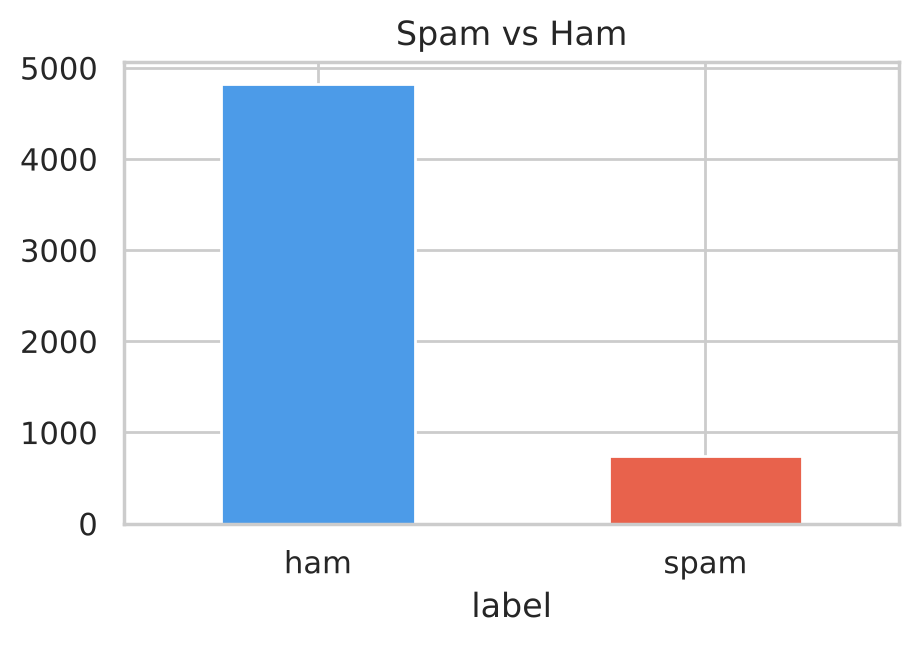

In [3]:
counts = df["label"].value_counts()
pct = (df["label"].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({"count": counts, "percent": pct}))
counts.plot(kind="bar", color=["#4c9be8", "#e8624c"], title="Spam vs Ham", rot=0, figsize=(5, 3))
plt.show()

**Observation:** The data is **imbalanced**, with ham far more common than spam. Plain accuracy can look good even for a weak model, so we look at precision, recall and F1 as well.

## 2. Text Preprocessing Pipeline
Lowercase → remove punctuation and digits-only noise → remove stopwords → stemming (optional step).

In [4]:
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def clean_text(text):
    text = text.lower()                                              # 1. lowercase
    text = text.translate(str.maketrans("", "", string.punctuation))  # 2. remove punctuation
    tokens = [w for w in text.split() if w not in stop_words]         # 3. remove stopwords
    tokens = [stemmer.stem(w) for w in tokens]                        # 4. stemming
    return " ".join(tokens)

df["clean"] = df["message"].apply(clean_text)
df[["message", "clean"]].head()

,message,clean
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri 2 wkli comp win fa cup final tkt 21...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goe usf live around though


In [5]:
df = df.drop_duplicates(subset="message").reset_index(drop=True)   # exact duplicate messages would leak between train and test
df["target"] = (df["label"] == "spam").astype(int)                  # spam = 1 (positive class)
print("After removing duplicates:", df.shape)
print(df["label"].value_counts())

After removing duplicates: (5171, 4)
label
ham     4518
spam     653
Name: count, dtype: int64


## 3. Feature Extraction: TF-IDF
**What does TF-IDF measure?** TF-IDF (*Term Frequency – Inverse Document Frequency*) scores how important a word is to a message relative to all messages.
- **TF** is how often the word appears in this message.
- **IDF** down-weights words that appear in many messages (like "u" or "get") and up-weights rare, distinctive ones (like "prize" or "claim").

Words that are frequent in one message but rare overall get a high score. That makes them good clues for telling spam from ham.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["target"], test_size=0.2, random_state=42, stratify=df["target"])
print("Train:", X_train.shape, " Test:", X_test.shape)

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)   # fit on train only to avoid data leakage
X_test_vec = tfidf.transform(X_test)
print("TF-IDF matrix:", X_train_vec.shape)

Train: (4136,)  Test: (1035,)


TF-IDF matrix: (4136, 5000)


## 4. Train Classifiers
Multinomial Naive Bayes is the standard choice for text. We also train Logistic Regression and a Linear SVM for comparison.

In [7]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Linear SVM": LinearSVC(class_weight="balanced"),
}
preds = {}
for name, m in models.items():
    m.fit(X_train_vec, y_train)
    preds[name] = m.predict(X_test_vec)
print("Models trained.")

Models trained.


## 5. Evaluation

In [8]:
rows = []
for name, p in preds.items():
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p),
                 "F1": f1_score(y_test, p)})
results = pd.DataFrame(rows).set_index("Model").round(4).sort_values("F1", ascending=False)
results

,Accuracy,Precision,Recall,F1
Model,,,,
Linear SVM,0.9778,0.9154,0.9084,0.9119
Multinomial Naive Bayes,0.9749,0.9487,0.8473,0.8952
Logistic Regression,0.9691,0.8613,0.9008,0.8806


In [9]:
for name, p in preds.items():
    print("=" * 55); print(name); print("=" * 55)
    print(classification_report(y_test, p, target_names=["ham", "spam"]))

Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham       0.98      0.99      0.99       904
        spam       0.95      0.85      0.90       131

    accuracy                           0.97      1035
   macro avg       0.96      0.92      0.94      1035
weighted avg       0.97      0.97      0.97      1035

Logistic Regression
              precision    recall  f1-score   support

         ham       0.99      0.98      0.98       904
        spam       0.86      0.90      0.88       131

    accuracy                           0.97      1035
   macro avg       0.92      0.94      0.93      1035
weighted avg       0.97      0.97      0.97      1035

Linear SVM
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       904
        spam       0.92      0.91      0.91       131

    accuracy                           0.98      1035
   macro avg       0.95      0.95      0.95      1035
weighted avg       

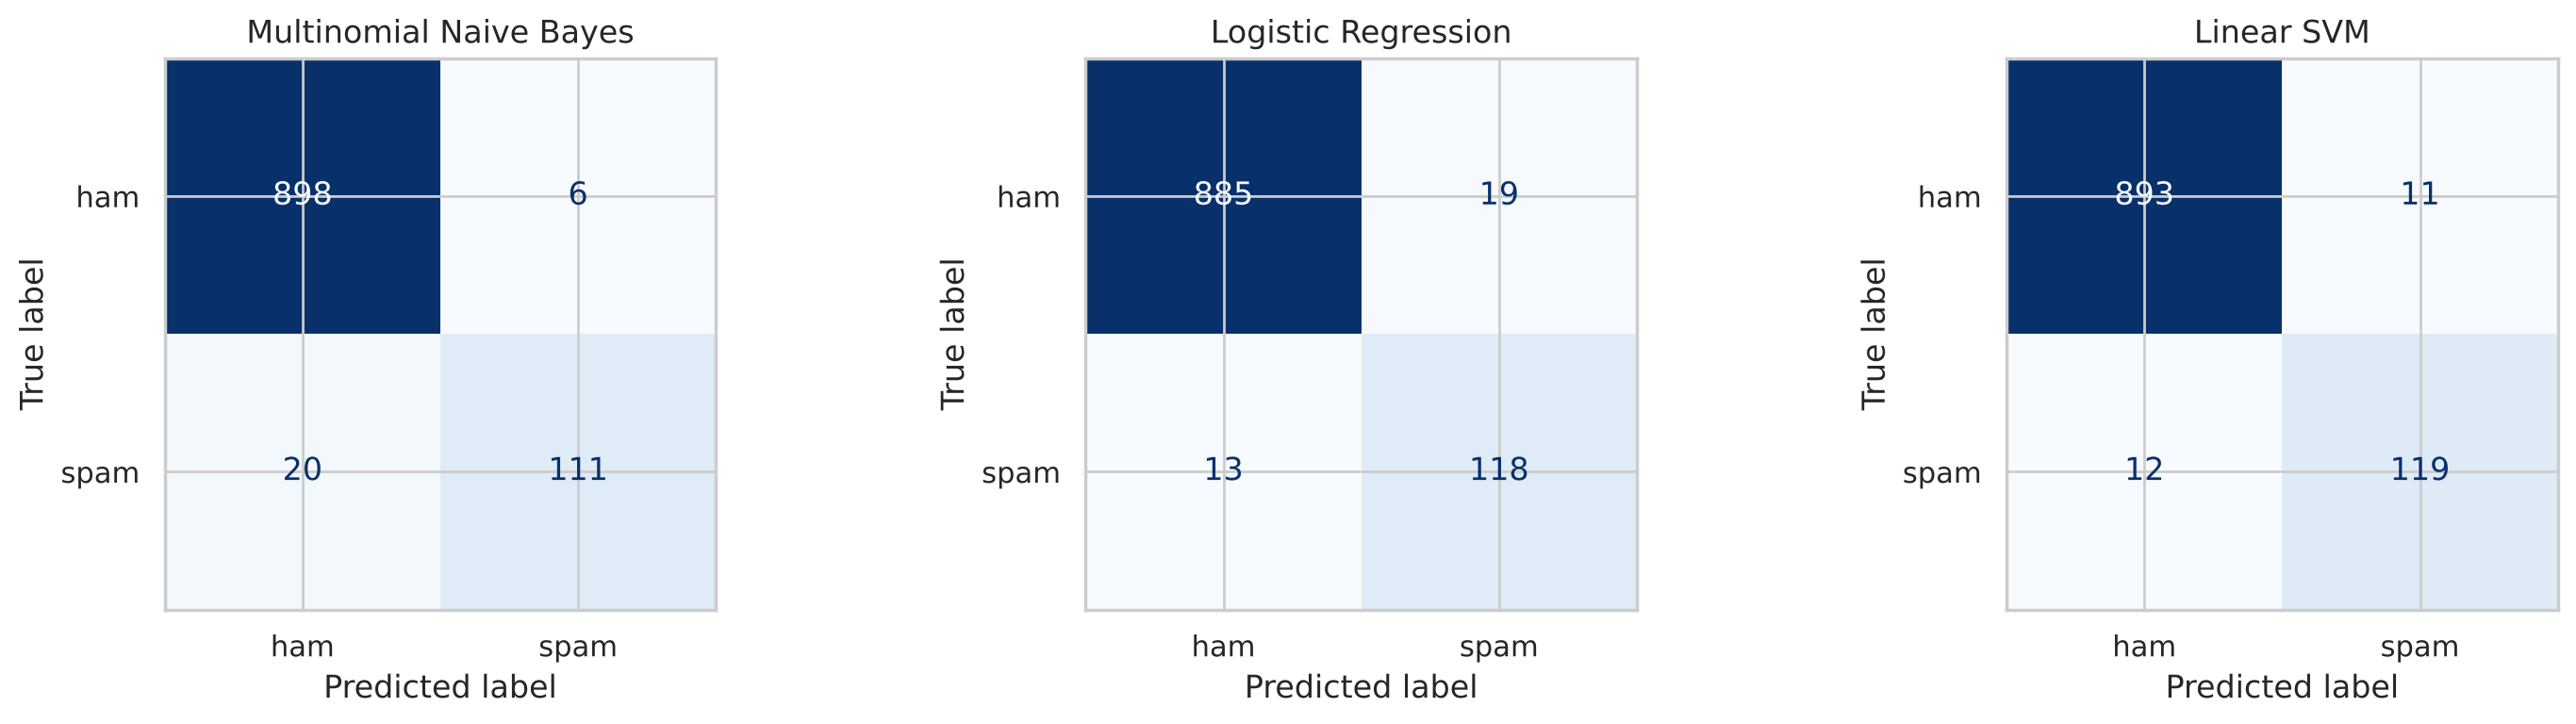

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [11]:
best = results["F1"].idxmax()
print("Best model by F1:", best)

Best model by F1: Linear SVM


## 6. Why Is Recall Important for Spam Detection?
**Recall** = of all the real spam messages, how many did the model catch? Low recall means spam slips through into the inbox, where it can carry phishing links, scams or malware, and the filter fails at its main job.

**But recall alone is not enough.** The opposite error is also costly. A *false positive* (a genuine message marked as spam) can hide an important email, such as a bank alert, an OTP or a job offer. So real systems balance **recall** (catch the spam) with **precision** (don't flag good mail), and the **F1-score** summarises both.

## 7. (Bonus) Word Clouds

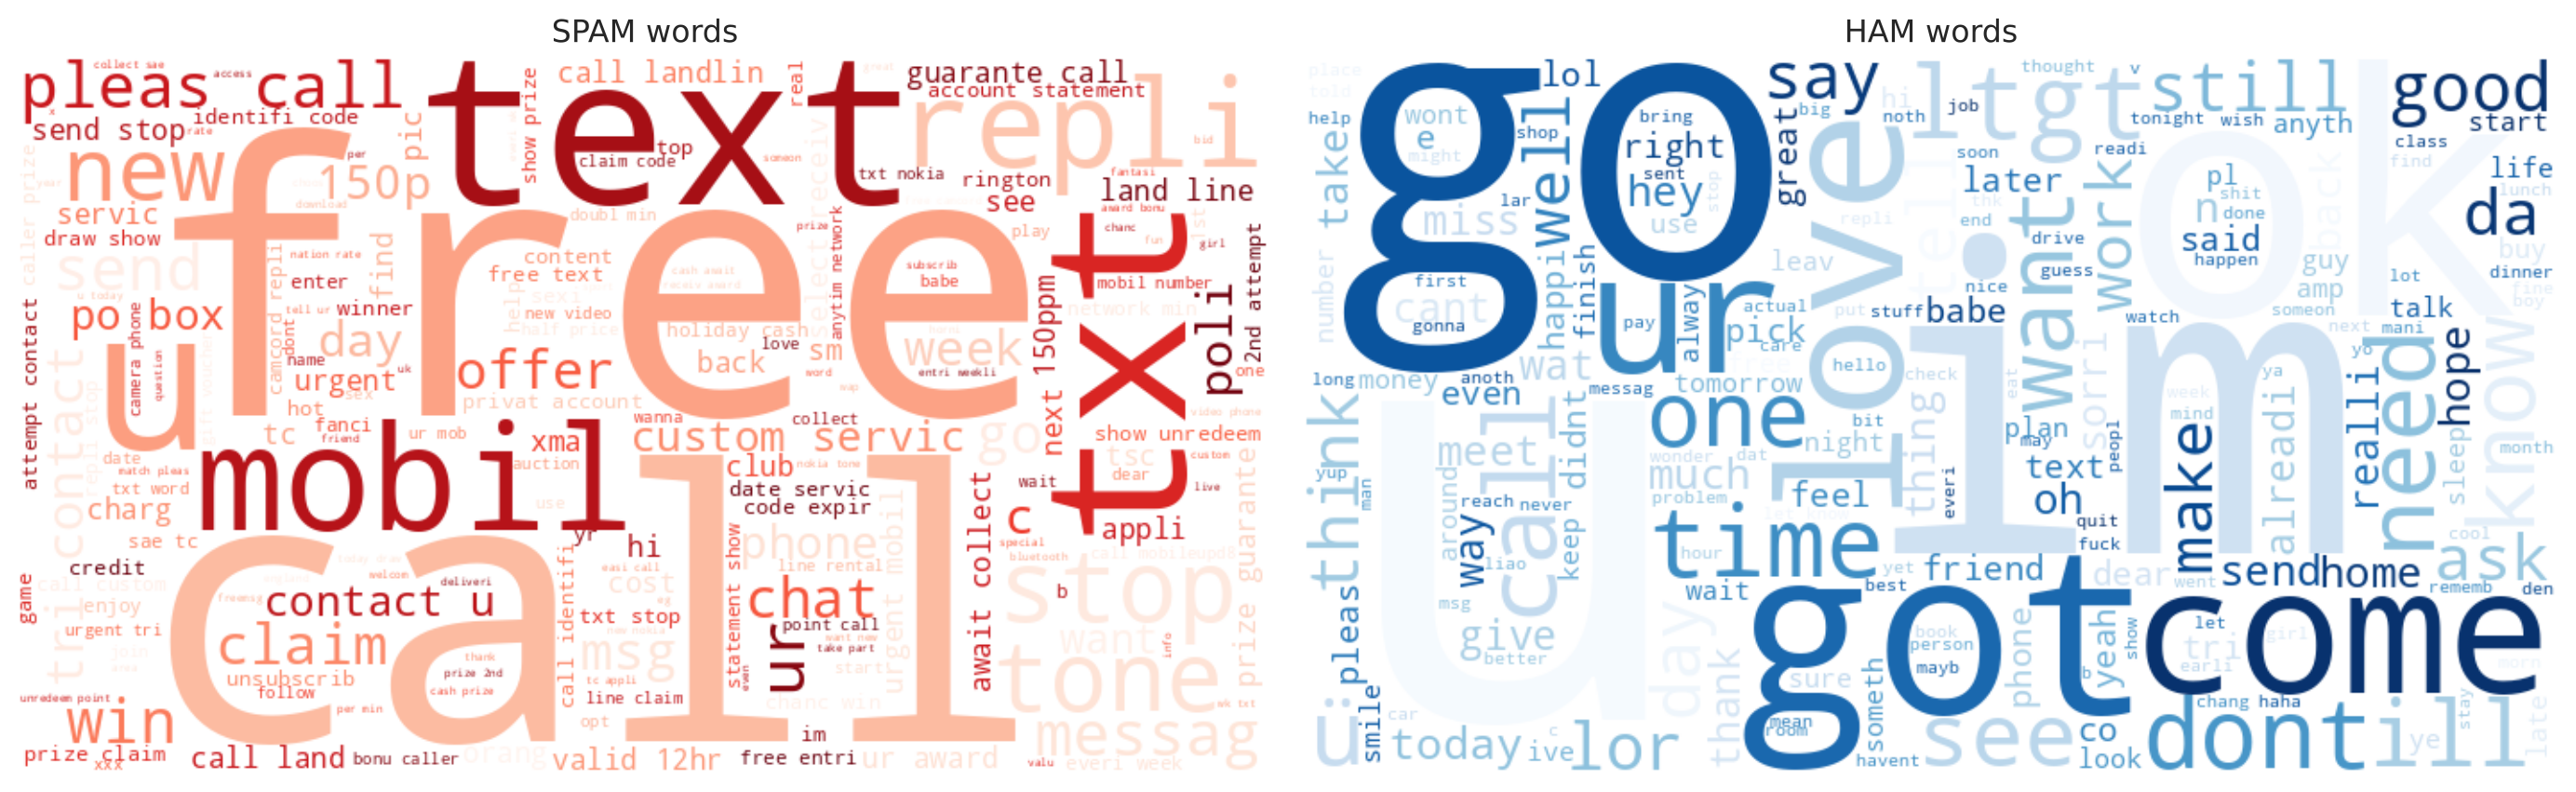

In [12]:
from wordcloud import WordCloud
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (lab, color) in zip(axes, [("spam", "Reds"), ("ham", "Blues")]):
    text = " ".join(df.loc[df["label"] == lab, "clean"])
    wc = WordCloud(width=700, height=400, background_color="white", colormap=color).generate(text)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"{lab.upper()} words")
plt.tight_layout(); plt.show()

## 8. Try It on New Messages

In [13]:
best_model = models[best]
samples = ["Congratulations! You have won a free prize. Call now to claim your reward",
           "Hey, are we still meeting for lunch tomorrow?",
           "URGENT! Your account has been selected for a cash prize, text WIN to 80085"]
for s in samples:
    label = best_model.predict(tfidf.transform([clean_text(s)]))[0]
    print(("SPAM" if label else "HAM "), "|", s)

SPAM | Congratulations! You have won a free prize. Call now to claim your reward
HAM  | Hey, are we still meeting for lunch tomorrow?
SPAM | URGENT! Your account has been selected for a cash prize, text WIN to 80085


## 9. Conclusion

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Linear SVM | 0.978 | 0.915 | 0.908 | **0.912** |
| Multinomial Naive Bayes | 0.975 | 0.949 | 0.847 | 0.895 |
| Logistic Regression | 0.969 | 0.861 | 0.901 | 0.881 |

- **Best model by F1: Linear SVM.** It has the best balance of catching spam (recall 90.8%) and not flagging good messages (precision 91.5%).
- **Naive Bayes** has the highest precision (94.9%), so it rarely marks a genuine message as spam, but it misses more spam (recall 84.7%). If wrongly blocking real messages is the bigger worry, it is a reasonable choice.
- **Accuracy is misleading here.** About 87% of messages are ham, so a model that predicted "ham" every time would already score ~87% accuracy while catching zero spam. That is why precision, recall and F1 matter.
- **Data note:** 403 exact duplicate messages were removed before splitting so the same message could not appear in both train and test sets.
- **Limitations:** this dataset is SMS messages from the 2000s. Modern email spam is longer and more varied, so the model would need retraining on recent email data before real use.